# Acoustic Reception

In [3]:
from n23_fluctuations_ragland import tools
from matplotlib import pyplot as plt
import numpy as np
import xarray as xr
from dotenv import load_dotenv, find_dotenv
import os
import cmps
import colorsys
from tqdm import tqdm
import nescafe23 as n23

_ = load_dotenv(find_dotenv())

%config InlineBackend.figure_format = 'retina'

### Poster presentation settings

In [4]:
import matplotlib.font_manager as fm
from nescafe23 import get_data_dir

font_path = str(get_data_dir() / "fonts" / "RedHatDisplay-Medium.ttf")
fm.fontManager.addfont(font_path)

plt.rcParams['font.family'] = 'Red Hat Display'

In [5]:
# Define your colors
whoi_colors = ['#00B7BD', '#EE5340']

In [6]:
def lighten_color(hex_color, saturation_scale=0.5, lightness_scale=1.5):
    """
    Lighten a hex color similar to seaborn's tab20 palette
    
    Args:
        hex_color: Hex color string (e.g., '#1f77b4')
        saturation_scale: Multiply saturation by this (default 0.5)
        lightness_scale: Multiply lightness by this (default 1.5)
    """
    # Remove '#' if present
    hex_color = hex_color.lstrip('#')
    
    # Convert hex to RGB (0-1 range)
    r, g, b = tuple(int(hex_color[i:i+2], 16) / 255.0 for i in (0, 2, 4))
    
    # Convert RGB to HLS
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    
    # Adjust saturation and lightness
    s_new = min(1.0, s * saturation_scale)
    l_new = min(1.0, l * lightness_scale)
    
    # Convert back to RGB
    r_new, g_new, b_new = colorsys.hls_to_rgb(h, l_new, s_new)
    
    # Convert to hex
    return '#{:02x}{:02x}{:02x}'.format(
        int(r_new * 255),
        int(g_new * 255),
        int(b_new * 255)
    )

In [7]:
colors = [
    whoi_colors[0],
    lighten_color(whoi_colors[0], lightness_scale=2),
    whoi_colors[1],
    lighten_color(whoi_colors[1], lightness_scale=1.4, saturation_scale=1)
]

In [8]:
colors

['#00B7BD', '#9cdbde', '#EE5340', '#f7b6ae']

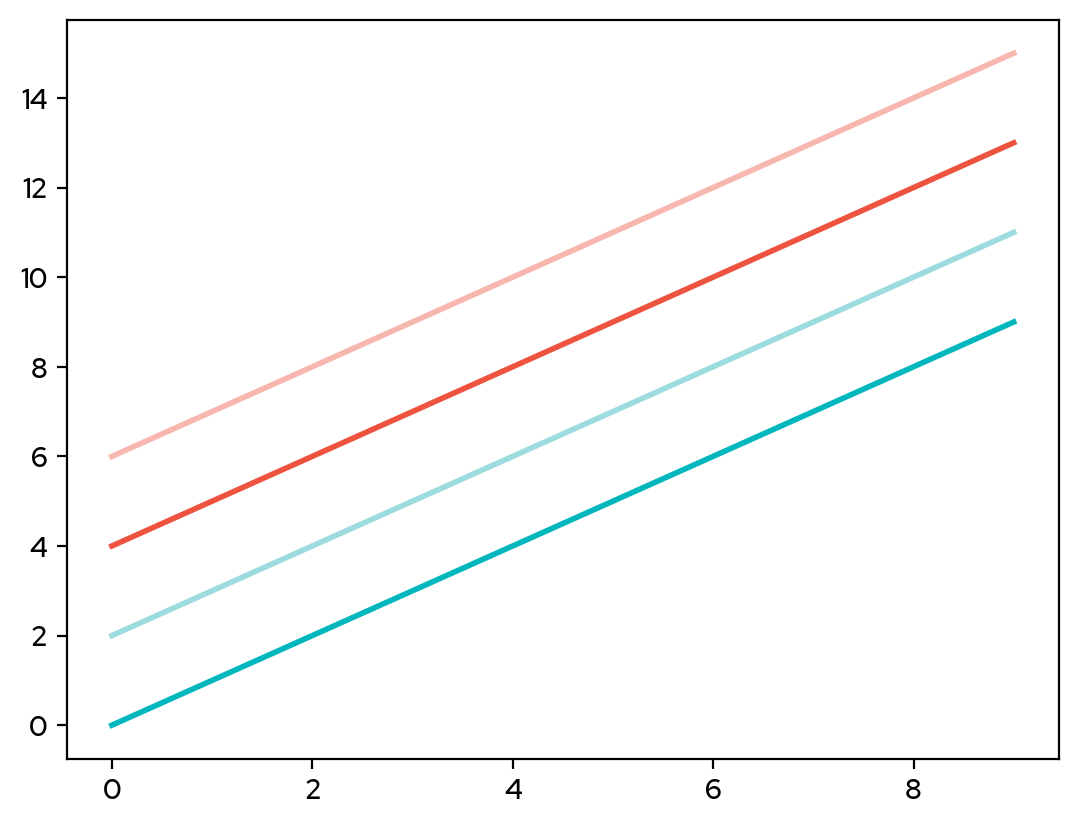

In [9]:
plt.plot(np.arange(0,10), lw=2, c=colors[0])
plt.plot(np.arange(2,12), lw=2, c=colors[1])
plt.plot(np.arange(4,14), lw=2, c=colors[2])
plt.plot(np.arange(6,16), lw=2, c=colors[3])

## Plot receptions

In [10]:
fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/mean_pulse_lower.nc"
mean_pulse_lower = xr.open_dataarray(fn)

fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/mean_pulse_upper.nc"
mean_pulse_upper = xr.open_dataarray(fn)

fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/mean_pulse_lower_noise.nc"
mean_pulse_lower_noise = xr.open_dataarray(fn)

fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/mean_pulse_upper_noise.nc"
mean_pulse_upper_noise = xr.open_dataarray(fn)



/home/john.ragland/Code/NESMA/NESCAFE23/.venv/bin/python: No module named pip


In [11]:
dss = tools.open_receptions()

100%|██████████| 23/23 [00:16<00:00,  1.38it/s]


In [12]:
thetas = np.linspace(-40, 40, 200)

bf_lower = n23.ULA_conventional_beamform(
    dss[12][32:]
    .swap_dims({"hydrophone": "nominal_depth"})
    .rename({"nominal_depth": "depth"}),
    thetas,
)

bf_lower_noise = 20 * np.log10(
    np.sqrt(np.abs(bf_lower.sel({"time": slice(90, 95)}) ** 2).mean(dim="time"))
)

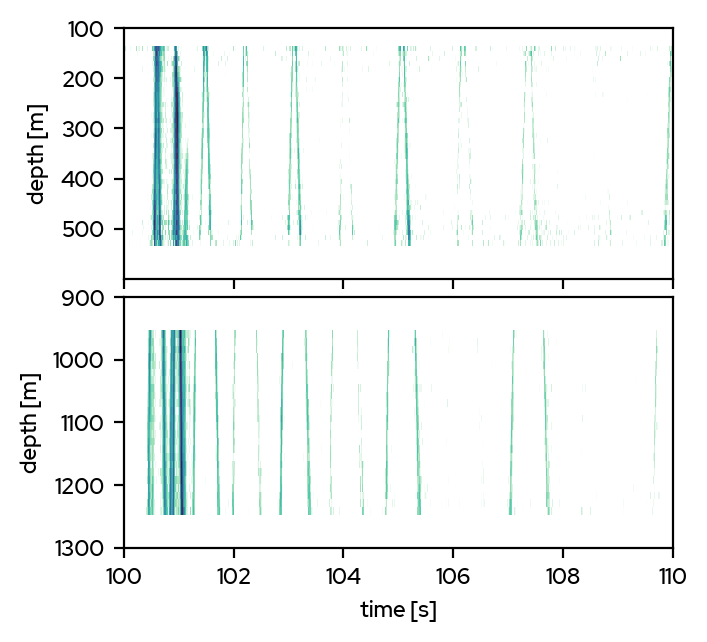

In [13]:
plt.rcParams.update({'font.size':'8'})
plt.rcParams.update({"text.usetex": False})

fig = plt.figure(figsize=(3.33, 3))

plt.subplot(2,1,1)

(20*np.log10(np.abs(mean_pulse_upper)) - mean_pulse_upper_noise).plot(add_colorbar=False, vmax=35, vmin=3, cmap=cmps.mako_r_white())


plt.xlim([100,110])
plt.ylim([600,100])
plt.ylabel('depth [m]')
plt.xlabel('')
plt.gca().set_xticklabels('')
plt.yticks(np.arange(500, 99, -100))

plt.subplot(2,1,2)
(20*np.log10(np.abs(mean_pulse_lower)) - mean_pulse_lower_noise).sel({'depth':slice(950, 1250)}).plot(vmax=35, vmin=3, cmap=cmps.mako_r_white(), add_colorbar=False)

plt.xlim([100,110])
plt.ylim([1300,900])
plt.yticks(np.arange(1300,801,-100))

plt.ylabel('depth [m]')
plt.xlabel('time [s]')

plt.tight_layout(pad=0)

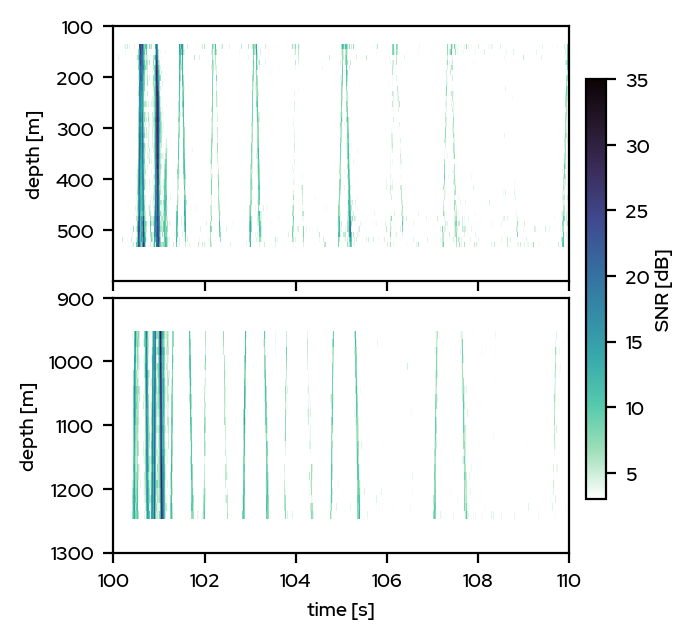

In [18]:
plt.rcParams.update({'font.size':'7'})
plt.rcParams.update({"text.usetex": False})

fig = plt.figure(figsize=(3.33, 3))

plt.subplot(2,1,1)
im1 = (20*np.log10(np.abs(mean_pulse_upper)) - mean_pulse_upper_noise).plot(add_colorbar=False, vmax=35, vmin=3, cmap=cmps.mako_r_white(), rasterized=True)

plt.xlim([100,110])
plt.ylim([600,100])
plt.ylabel('depth [m]')
plt.xlabel('')
plt.gca().set_xticklabels('')
plt.yticks(np.arange(500, 99, -100))

plt.subplot(2,1,2)
im2 = (20*np.log10(np.abs(mean_pulse_lower)) - mean_pulse_lower_noise).sel({'depth':slice(950, 1250)}).plot(vmax=35, vmin=3, cmap=cmps.mako_r_white(), add_colorbar=False, rasterized=True)

plt.xlim([100,110])
plt.ylim([1300,900])
plt.yticks(np.arange(1300,801,-100))

plt.ylabel('depth [m]')
plt.xlabel('time [s]')

plt.tight_layout(pad=0)

# Adjust subplot spacing to make room for colorbar
plt.subplots_adjust(right=0.825)

# Add a single colorbar for both subplots
cbar_ax = fig.add_axes([0.85, 0.2, 0.03, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(im2.collections[0] if hasattr(im2, 'collections') else im2, cax=cbar_ax)
cbar.set_label('SNR [dB]', labelpad=2)

fig.savefig('../../figures/presentation_figures/mean_pulse.pdf', dpi=300)

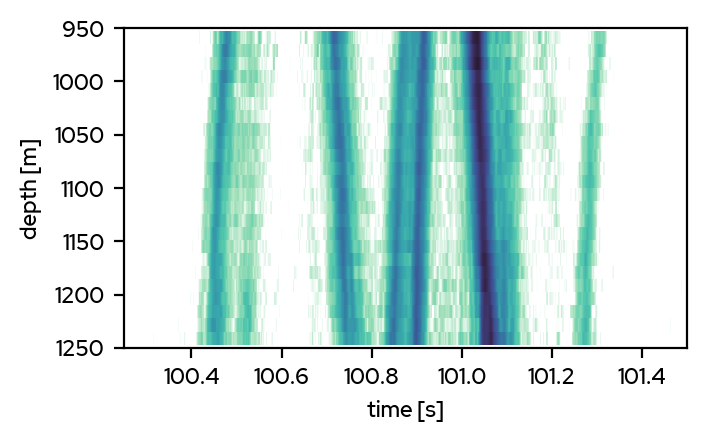

In [14]:
fig = plt.figure(figsize=(3.33, 2))

(20*np.log10(np.abs(mean_pulse_lower)) - mean_pulse_lower_noise).sel({'depth':slice(950, 1250)}).plot(vmax=35, vmin=3, cmap=cmps.mako_r_white(), add_colorbar=False, rasterized=True)

plt.xlim([100.25,101.5])
plt.ylim([1250,950])
#plt.yticks(np.arange(1300,801,-100))

plt.ylabel('depth [m]')
plt.xlabel('time [s]')

plt.tight_layout(pad=0)

fig.savefig('../../figures/presentation_figures/ducted_mean_pulse.png', dpi=300)

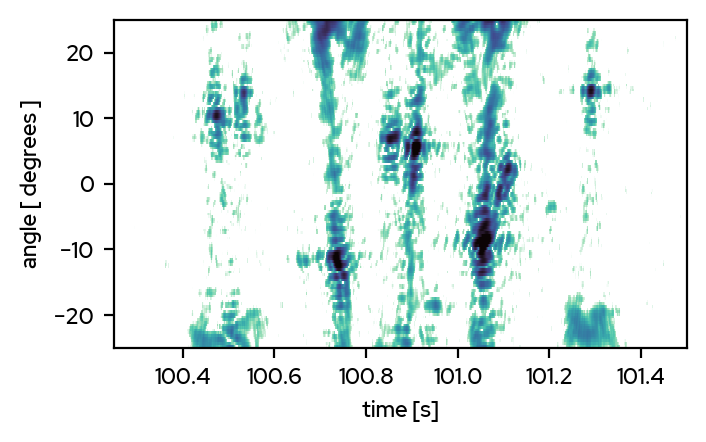

In [15]:
fig = plt.figure(figsize=(3.33, 2))


(20*np.log10(np.abs(bf_lower)) - bf_lower_noise).plot(x='time', cmap=cmps.mako_r_white(), vmin=8, vmax=35, add_colorbar=False, rasterized=True)

plt.ylabel('angle [ degrees ]')
plt.xlabel('time [s]')


plt.xlim([100.25,101.5])
plt.ylim([-25,25])

plt.tight_layout(pad=0)

fig.savefig('../../figures/presentation_figures/beamformed_arrival.png', dpi=300)

## Reception GIF

In [33]:
for Tx_num in tqdm(range(23)):
    fig = plt.figure(figsize=(10,6))
    fig.suptitle(f'Tx number: {Tx_num}')
    plt.subplot(2,1,1)
    (20*np.log10(np.abs(dss[Tx_num].swap_dims({"hydrophone":"actual_depth"})[:32]))-100).plot(x='time', add_colorbar=True, cbar_kwargs={'label':'SNR [dB]'}, vmin=0, vmax=30, cmap=cmps.mako_r_white())
    plt.ylabel('depth [m]')
    plt.xlabel('time [s]')
    plt.title('Upper Array', loc='left')

    plt.xlim([100,115])
    plt.ylim([550,150])

    plt.subplot(2,1,2)
    (20*np.log10(np.abs(dss[Tx_num].swap_dims({"hydrophone":"actual_depth"})[32:]))-100).plot(x='time', add_colorbar=True, cbar_kwargs={'label':'SNR [dB]'}, vmin=0, vmax=30, cmap=cmps.mako_r_white())
    plt.ylabel('depth [m]')
    plt.xlabel('time [s]')
    plt.title('Lower Array', loc='left')

    plt.xlim([100,115])
    plt.ylim([1300,900])

    plt.tight_layout()

    plt.savefig(f'animations/receptions_zoomed_out/{Tx_num:04}.png', dpi=300)
    plt.close()

  0%|          | 0/23 [00:00<?, ?it/s]/home/john.ragland/Code/NESMA/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
100%|██████████| 23/23 [00:54<00:00,  2.38s/it]


In [34]:
for Tx_num in tqdm(range(23)):
    fig = plt.figure(figsize=(5,6))
    fig.suptitle(f'Tx number: {Tx_num}')
    plt.subplot(2,1,1)
    (20*np.log10(np.abs(dss[Tx_num].swap_dims({"hydrophone":"actual_depth"})[:32]))-100).plot(x='time', add_colorbar=True, cbar_kwargs={'label':'SNR [dB]'}, vmin=0, vmax=30, cmap=cmps.mako_r_white())
    plt.ylabel('depth [m]')
    plt.xlabel('time [s]')
    plt.title('Upper Array', loc='left')

    plt.xlim([100.25,101.5])
    plt.ylim([550,150])

    plt.subplot(2,1,2)
    (20*np.log10(np.abs(dss[Tx_num].swap_dims({"hydrophone":"actual_depth"})[32:]))-100).plot(x='time', add_colorbar=True, cbar_kwargs={'label':'SNR [dB]'}, vmin=0, vmax=30, cmap=cmps.mako_r_white())
    plt.ylabel('depth [m]')
    plt.xlabel('time [s]')
    plt.title('Lower Array', loc='left')

    plt.xlim([100.25,101.5])
    plt.ylim([1300,900])

    plt.tight_layout()

    plt.savefig(f'animations/receptions_zoomed_in/{Tx_num:04}.png', dpi=300)
    plt.close()

100%|██████████| 23/23 [00:53<00:00,  2.32s/it]


In [35]:
input_files = 'animations/receptions_zoomed_out/%04d.png'
output_gif = 'animations/receptions_zoomed_out.gif'

cmd = f"ffmpeg -y -framerate 5 -i {input_files} -vf \"split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse\" {output_gif}"

os.system(cmd)

input_files = 'animations/receptions_zoomed_in/%04d.png'
output_gif = 'animations/receptions_zoomed_in.gif'

cmd = f"ffmpeg -y -framerate 5 -i {input_files} -vf \"split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse\" {output_gif}"

os.system(cmd)

ffmpeg version 6.1.1-3ubuntu5+esm7 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.3.0-6ubuntu2~24.04)
  configuration: --prefix=/usr --extra-version=3ubuntu5+esm7 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enabl

0